# Méthodes d'interpolations (1D)

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate

import matplotlib as mpl
plt.style.use('../../src/bip.mplstyle')

In [12]:
F = 1
c0 = "#008800"
c1 = "#0000ff"
c2 = "#cc0000"
c3 = (.6,0,.6)

def myplot(x1, y1, x2, y2, xx, yy, K, kind):
    
    N = len(x1)    
    fig, axs = plt.subplots(1, 3, figsize=(10,2))

    # Données source
    axs[0].plot(x1, y1, color='C0', linewidth=0, markersize=8, markeredgewidth=2, marker=".")
    axs[0].set_title("Input data", size=14)

    # Courbe d'interpolation
    axs[1].plot(xx, yy, color=c3, linewidth=.5)
    if kind == 'nearest':
        idx = range(4,6)
        axs[1].plot(xx[idx], yy[idx], color=c3, linewidth=2)
        axs[1].plot(x1[2], y1[2], color=c3, linewidth=0, markersize=10, markeredgewidth=2, marker="o", fillstyle='none')
    if kind == 'linear':
        idx = range(1,3)
        axs[1].plot(xx[idx], yy[idx], color=c3, linewidth=2)
        axs[1].plot(x1[1:3], y1[1:3], color=c3, linewidth=0, markersize=10, markeredgewidth=2, marker="o", fillstyle='none')
    if kind == 'cubic':
        idx = range(10,20)
        axs[1].plot(xx[idx], yy[idx], color=c3, linewidth=2)
        axs[1].plot(x1[:4], y1[:4], color=c3, linewidth=0, markersize=10, markeredgewidth=2, marker="o", fillstyle='none')
    axs[1].plot(x1, y1, color='C0', linewidth=0, markersize=8, markeredgewidth=2, marker=".")
    axs[1].set_title('Input data and "continuous" data', size=14)
    
    # Données interpolées
    axs[2].plot(xx, yy, color=c3, linewidth=.5)
    axs[2].plot(x2, y2, color='r', linewidth=0, markersize=8, marker=".")
    axs[2].set_title("Output data", size=14)

    # Axes
    for k in range(3):
        axs[k].set_xlim(-.2,N-.8)
        # axs[k].set_ylim(0,1)
        axs[k].set_xticks(range(0,N))
        axs[k].set_yticks(np.arange(0,1.1,.25), labels=[])
        axs[k].grid()
        
    # Affichage et enregistrement
    plt.savefig(f"interp-{kind}-1d.svg", bbox_inches='tight')
    plt.show()

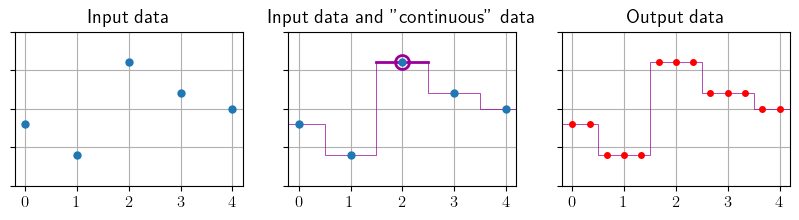

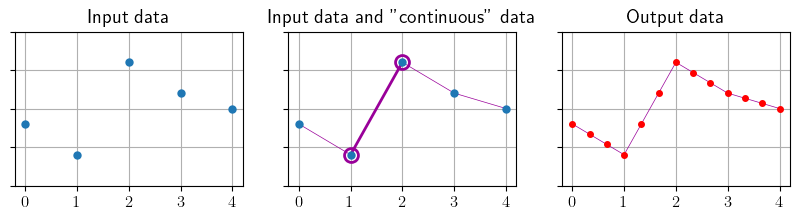

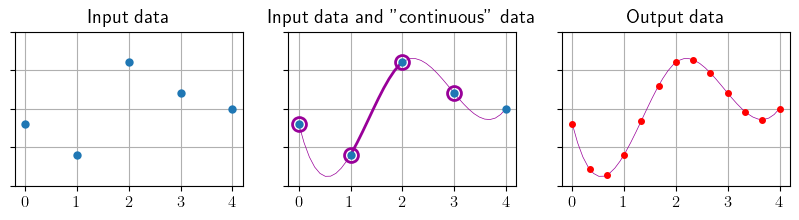

In [13]:
# Données
y1 = np.array([.4, .2, .8, .6, .5])
N = len(y1)
x1 = np.arange(N)

# Interpolation d'un facteur K
K = 3
x2 = np.arange(0, N-.999, 1/K)

# Interpolation linéaire
for kind in ['nearest', 'linear', 'cubic']:
    
    # Interpolation
    f = interpolate.interp1d(x1, y1, kind=kind)
    y2 = f(x2)
    
    # Courbe d'interpolation
    xx = np.array([])
    yy = np.array([])
    if kind == 'nearest':
        for i in range(N):
            xx = np.append(xx, [x1[i]-.5,x1[i]+.5])
            yy = np.append(yy, [y1[i],y1[i]])
    if kind == 'linear':
        xx = x1
        yy = y1
    if kind == 'cubic':
        xx = np.linspace(0,N-1,40)
        yy = f(xx)
    
    # Affichage et enregistrement
    myplot(x1, y1, x2, y2, xx, yy, K, kind)